Perform adversarial testing by slightly modifying input features using perturbation techniques, manually designing worst-case adversarial samples, and quantifying their impact on model robustness.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()
X, y = df[features], df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def create_model():
    return make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100, max_depth=10,
            random_state=42, class_weight="balanced"
        )
    )

model = create_model()
model.fit(X_train, y_train)

baseline_pred = model.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred, zero_division=0)

print("Baseline accuracy:", round(baseline_acc, 4))
print("Baseline F1:", round(baseline_f1, 4))

Baseline accuracy: 0.75
Baseline F1: 0.8333


In [3]:
rng = np.random.default_rng(42)
stds = X_train.std().replace(0, 1)
lower = X_train.min()
upper = X_train.max()

perturbation_results = []

for level in [0.01, 0.03, 0.05, 0.10, 0.20]:
    noisy_X = X_test.copy()

    noise = rng.normal(
    0, level, size=noisy_X[features].shape
) * stds[features].to_numpy()

    noisy_X[features] = np.clip(
    noisy_X[features].to_numpy() + noise,
    lower[features].to_numpy(),
    upper[features].to_numpy()
)

    pred = model.predict(noisy_X)

    perturbation_results.append({
        "Noise Level (std)": level,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "Changed Predictions": np.sum(pred != baseline_pred)
    })

perturbation_df = pd.DataFrame(perturbation_results)
print(perturbation_df.round(4).to_string(index=False))

 Noise Level (std)  Accuracy  F1 Score  Changed Predictions
              0.01    0.7500    0.8333                    0
              0.03    0.7500    0.8333                    0
              0.05    0.7500    0.8333                    0
              0.10    0.8125    0.8800                    1
              0.20    0.6875    0.8000                    1


In [4]:
def worst_case_sample(patient, epsilon=0.05, steps=5):
    original_pred = model.predict(patient.to_frame().T)[0]
    original_prob = model.predict_proba(patient.to_frame().T)[0, original_pred]

    best_sample = patient.copy()
    best_confidence = original_prob

    for feature in features:
        for direction in [-1, 1]:
            for step in range(1, steps + 1):
                candidate = patient.copy()

                change = direction * epsilon * step * stds[feature]
                candidate[feature] = np.clip(
                    patient[feature] + change,
                    lower[feature],
                    upper[feature]
                )

                candidate_pred = model.predict(candidate.to_frame().T)[0]
                candidate_prob = model.predict_proba(
                    candidate.to_frame().T
                )[0, original_pred]

                if candidate_prob < best_confidence:
                    best_confidence = candidate_prob
                    best_sample = candidate.copy()

                if candidate_pred != original_pred:
                    return candidate, original_pred, candidate_pred

    return best_sample, original_pred, model.predict(
        best_sample.to_frame().T
    )[0]


sample = X_test.iloc[0]
adversarial_sample, original_class, changed_class = worst_case_sample(sample)

print("Original sample:")
print(sample)

print("\nPerturbed sample:")
print(adversarial_sample)

print("\nOriginal prediction:", original_class)
print("Perturbed prediction:", changed_class)

Original sample:
age          31.0
trestbps    134.0
chol        255.0
thalach     174.0
oldpeak       4.1
Name: 49, dtype: float64

Perturbed sample:
age          34.715578
trestbps    134.000000
chol        255.000000
thalach     174.000000
oldpeak       4.100000
Name: 49, dtype: float64

Original prediction: 0
Perturbed prediction: 0


In [5]:
def make_worst_case(patient):
    adversarial, _, _ = worst_case_sample(patient)
    return adversarial

adversarial_X = pd.DataFrame(
    [make_worst_case(row) for _, row in X_test.iterrows()],
    columns=features,
    index=X_test.index
)

adversarial_pred = model.predict(adversarial_X)

robustness = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "F1 Score",
        "Prediction Change Rate"
    ],
    "Original": [
        accuracy_score(y_test, baseline_pred),
        f1_score(y_test, baseline_pred, zero_division=0),
        0
    ],
    "Perturbed": [
        accuracy_score(y_test, adversarial_pred),
        f1_score(y_test, adversarial_pred, zero_division=0),
        np.mean(adversarial_pred != baseline_pred)
    ]
})

print(robustness.round(4).to_string(index=False))

                Metric  Original  Perturbed
              Accuracy    0.7500     0.7500
              F1 Score    0.8333     0.8462
Prediction Change Rate    0.0000     0.1250


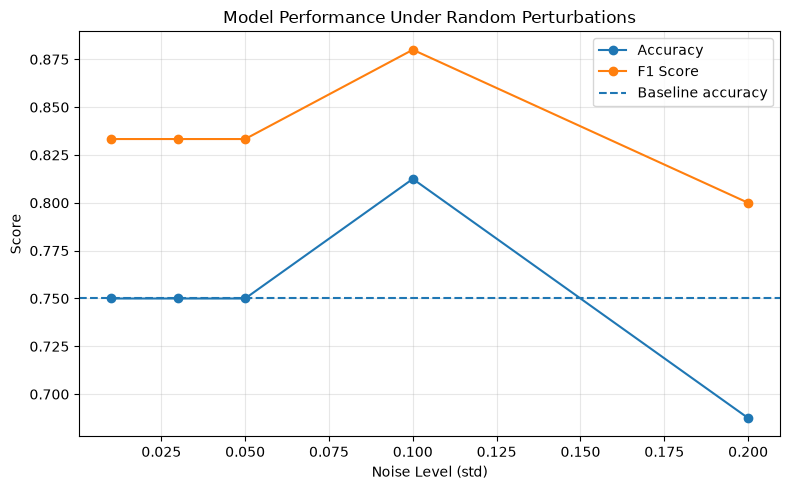

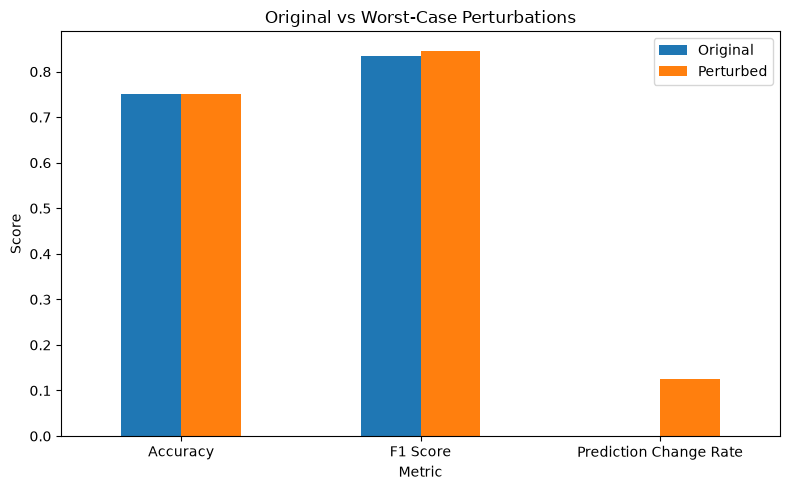

In [6]:
perturbation_df.set_index("Noise Level (std)")[
    ["Accuracy", "F1 Score"]
].plot(marker="o", figsize=(8, 5))

plt.axhline(baseline_acc, linestyle="--", label="Baseline accuracy")
plt.title("Model Performance Under Random Perturbations")
plt.ylabel("Score")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

robustness.set_index("Metric").plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Original vs Worst-Case Perturbations")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
print("Adversarial Robustness Summary")
print("Baseline accuracy:", round(baseline_acc, 4))
print("Worst-case accuracy:", round(
    accuracy_score(y_test, adversarial_pred), 4
))
print("Prediction change rate:", round(
    np.mean(adversarial_pred != baseline_pred), 4
))

print("\nConclusion:")
print("- Lower accuracy indicates sensitivity to the tested perturbations.")
print("- Prediction change rate measures how often the model changes its decision.")
print("- Check whether perturbed records remain realistic before interpreting results.")

Adversarial Robustness Summary
Baseline accuracy: 0.75
Worst-case accuracy: 0.75
Prediction change rate: 0.125

Conclusion:
- Lower accuracy indicates sensitivity to the tested perturbations.
- Prediction change rate measures how often the model changes its decision.
- Check whether perturbed records remain realistic before interpreting results.
